In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from google.colab import files
import os
import gc
import math
import time
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import TargetEncoder
from sklearn.model_selection import RandomizedSearchCV

## **Recopilación de Datos**

In [2]:
def crear_sesion(retries=5, backoff_factor=1.0):
  session = requests.Session()
  retry = Retry(
      total=retries,
      read=retries,
      connect=retries,
      backoff_factor=backoff_factor,
      status_forcelist=[429, 500, 502, 503, 504],
      allowed_methods=["GET"],
  )
  adapter = HTTPAdapter(max_retries=retry)
  session.mount("http://", adapter)
  session.mount("https://", adapter)
  return session


def descargar_json_a_csv(url, csv_path, timeout=120):
  if os.path.exists(csv_path):
    print(f"Cargando {csv_path} desde disco...")
    return pd.read_csv(csv_path)

  print(f"Descargando {csv_path}...")
  session = crear_sesion()
  resp = session.get(url, timeout=timeout)
  resp.raise_for_status()

  payload = resp.json()
  records = payload.get("data", [])
  df = pd.DataFrame(records)
  df.to_csv(csv_path, index=False)
  print(f"Guardado {csv_path} ({len(df)} filas).")
  return df

url = (
    "https://www.economia.gob.mx/apidatamexico/tesseract/data.jsonrecords?Academic+Degree=11&Nation=mex&Year=2020%2C2021%2C2022&cube=anuies_enrollment&drilldowns=State%2CArea%2CCareer%2CInstitution%2CAcademic+Degree%2CAge+Group%2CSex%2CYear&locale=es&measures=Students&parents=false"
)
DF = descargar_json_a_csv(url, "educacion_superior.csv", timeout=180)

Descargando educacion_superior.csv...
Guardado educacion_superior.csv (1042410 filas).


In [3]:
DF.head(5)

,State ID,State,Area ID,Area,Career ID,Career,Institution ID,Institution,Academic Degree ID,Academic Degree,Age Group ID,Age Group,Sex ID,Sex,Year,Students
0,1,Aguascalientes,1,Educación,03ec426a7d98355cd8e8bd5e5561b659c76a9b4d3eeb2f...,Licenciatura en enseñanza del idioma inglés,29,Universidad Del Desarrollo Profesional,11,Licenciatura,0,17,2,Mujer,2022,1
1,1,Aguascalientes,1,Educación,102fd7676a6071d398d6abc3ace3326d8d66672449a700...,Licenciatura en docencia de francés y español ...,40,Universidad Autónoma De Aguascalientes,11,Licenciatura,0,17,1,Hombre,2020,1
2,1,Aguascalientes,1,Educación,102fd7676a6071d398d6abc3ace3326d8d66672449a700...,Licenciatura en docencia de francés y español ...,40,Universidad Autónoma De Aguascalientes,11,Licenciatura,1,18,1,Hombre,2020,5
3,1,Aguascalientes,1,Educación,102fd7676a6071d398d6abc3ace3326d8d66672449a700...,Licenciatura en docencia de francés y español ...,40,Universidad Autónoma De Aguascalientes,11,Licenciatura,1,18,2,Mujer,2020,15
4,1,Aguascalientes,1,Educación,102fd7676a6071d398d6abc3ace3326d8d66672449a700...,Licenciatura en docencia de francés y español ...,40,Universidad Autónoma De Aguascalientes,11,Licenciatura,2,19,1,Hombre,2020,7


## **Comprensión de los Datos**

In [4]:
sns.set_theme(style="whitegrid")


def auditar_df(df, nombre="DF (educacion_superior)"):
  print(f"=== AUDITORÍA DE {nombre} ===")
  print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas\n")

  print("Tipos de datos:")
  print(df.dtypes, "\n")

  nulos = df.isna().sum()
  pct_nulos = (df.isna().mean() * 100).round(2)
  resumen_nulos = pd.DataFrame({"nulos": nulos, "%_nulos": pct_nulos})
  faltantes = resumen_nulos[resumen_nulos["nulos"] > 0]
  print("Valores faltantes:")
  print(faltantes if not faltantes.empty else "Sin valores nulos explícitos", "\n")

  duplicados = df.duplicated().sum()
  print(f"Filas duplicadas exactas: {duplicados}\n")

  num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
  if num_cols:
    print("Estadísticas de variables numéricas:")
    print(
        df[num_cols]
        .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
        .T[["count", "mean", "std", "min", "25%", "50%", "75%", "95%", "max"]],
        "\n",
    )

  cat_cols = df.select_dtypes(
      include=["object", "category", "string"]
  ).columns.tolist()
  if cat_cols:
    print("Estadísticas de variables categóricas:")
    for col in cat_cols:
      n_unicos = df[col].nunique(dropna=True)
      top3 = df[col].value_counts(dropna=False).head(3).to_dict()
      print(f"  - {col} ({n_unicos} valores únicos): {top3}")


auditar_df(DF)

=== AUDITORÍA DE DF (educacion_superior) ===
Dimensiones: 1042410 filas x 16 columnas

Tipos de datos:
State ID               int64
State                 object
Area ID                int64
Area                  object
Career ID             object
Career                object
Institution ID         int64
Institution           object
Academic Degree ID     int64
Academic Degree       object
Age Group ID           int64
Age Group             object
Sex ID                 int64
Sex                   object
Year                   int64
Students               int64
dtype: object 

Valores faltantes:
Sin valores nulos explícitos 

Filas duplicadas exactas: 0

Estadísticas de variables numéricas:
                        count         mean          std     min     25%  \
State ID            1042410.0    17.756128     8.583808     1.0    11.0   
Area ID             1042410.0     4.861497     2.460035     1.0     3.0   
Institution ID      1042410.0  1535.757599  1119.989832     1.0   526.0   
A

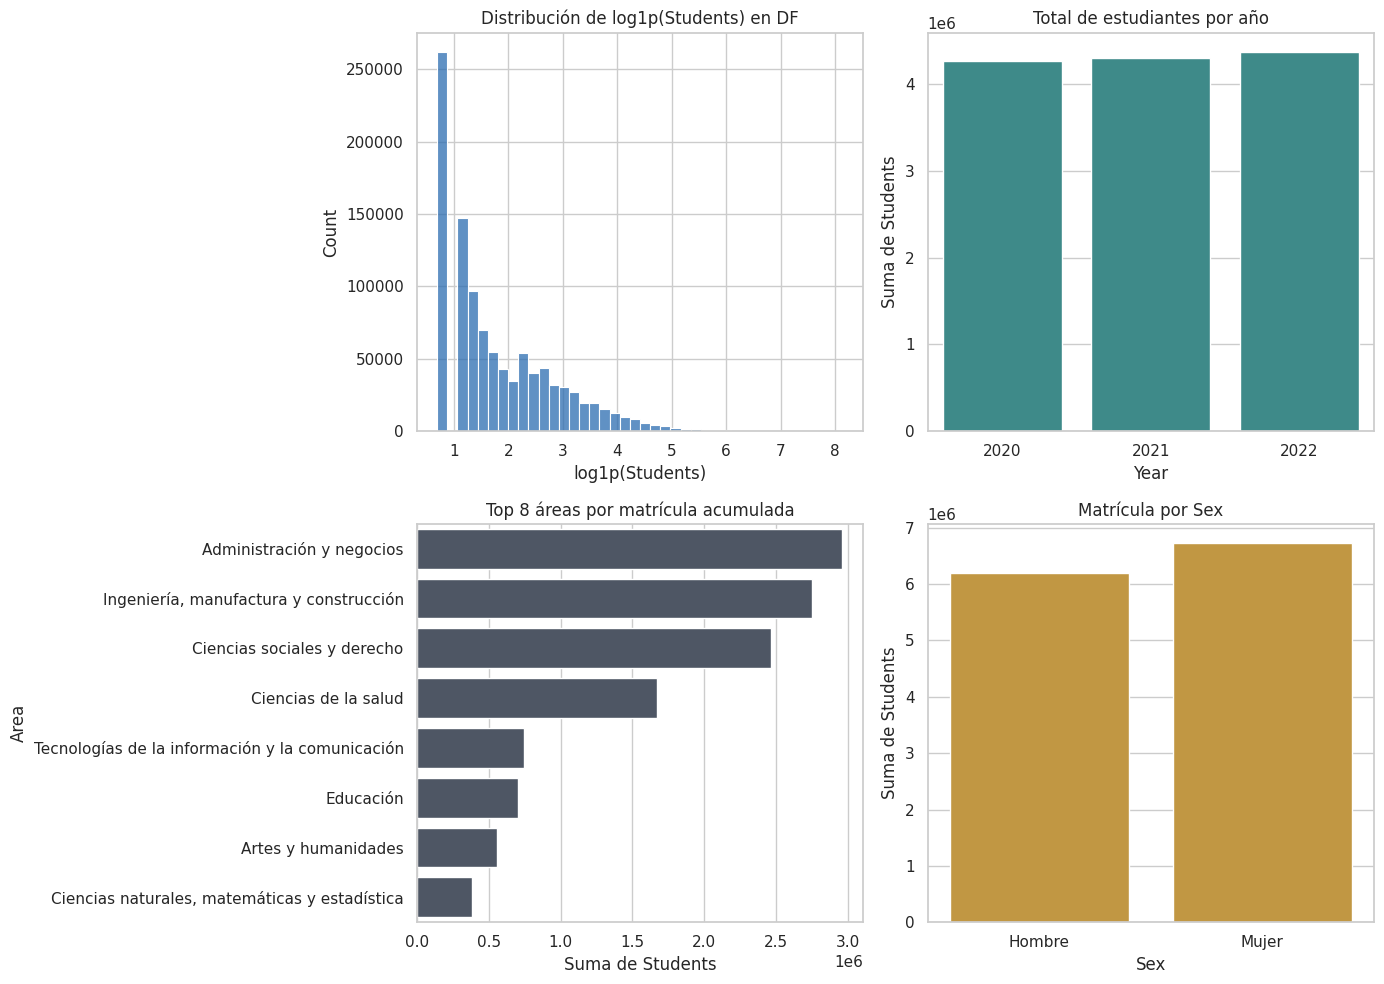

In [5]:
def graficar_df_comprension(df):
  fig, axes = plt.subplots(2, 2, figsize=(14, 10))

  # 1. Distribución de Students y log1p(Students)
  if "Students" in df.columns:
    s_num = pd.to_numeric(df["Students"], errors="coerce").dropna()
    sns.histplot(np.log1p(s_num), bins=40, ax=axes[0, 0], color="#2b6cb0")
    axes[0, 0].set_title("Distribución de log1p(Students) en DF")
    axes[0, 0].set_xlabel("log1p(Students)")

  # 2. Matrícula total por Year
  if "Year" in df.columns and "Students" in df.columns:
    por_anio = df.groupby("Year", as_index=False)["Students"].sum()
    sns.barplot(
        data=por_anio, x="Year", y="Students", ax=axes[0, 1], color="#319795"
    )
    axes[0, 1].set_title("Total de estudiantes por año")
    axes[0, 1].set_ylabel("Suma de Students")

  # 3. Top 8 áreas por matrícula
  if "Area" in df.columns and "Students" in df.columns:
    top_area = (
        df.groupby("Area", as_index=False)["Students"]
        .sum()
        .sort_values("Students", ascending=False)
        .head(8)
    )
    sns.barplot(
        data=top_area, y="Area", x="Students", ax=axes[1, 0], color="#4a5568"
    )
    axes[1, 0].set_title("Top 8 áreas por matrícula acumulada")
    axes[1, 0].set_xlabel("Suma de Students")

  # 4. Matrícula por Sex
  if "Sex" in df.columns and "Students" in df.columns:
    por_sexo = df.groupby("Sex", as_index=False)["Students"].sum()
    sns.barplot(
        data=por_sexo, x="Sex", y="Students", ax=axes[1, 1], color="#d69e2e"
    )
    axes[1, 1].set_title("Matrícula por Sex")
    axes[1, 1].set_ylabel("Suma de Students")

  plt.tight_layout()
  plt.show()


graficar_df_comprension(DF)

## **Preprocesamiento**

In [6]:
def limpiar_y_guardar_df_parquet(
    df_raw,
    ruta_parquet="educacion_superior_limpio.parquet",
    cols_a_eliminar=None,
):
  df = df_raw.copy()

  df.columns = [
      c.strip().lower().replace(" ", "_").replace("-", "_") for c in df.columns
  ]

  antes = len(df)
  df = df.drop_duplicates().reset_index(drop=True)
  print(f"Duplicados eliminados: {antes - len(df)} | Filas: {len(df)}")

  if "sex" in df.columns:
    sexo_norm = df["sex"].astype(str).str.strip().str.lower()
    mapa_sexo = {
        "hombre": 1,
        "masculino": 1,
        "male": 1,
        "m": 1,
        "1": 1,
        "mujer": 0,
        "femenino": 0,
        "female": 0,
        "f": 0,
        "0": 0,
    }
    df["sex"] = sexo_norm.map(mapa_sexo)
    print("Conteo de sex:")
    print(df["sex"].value_counts(dropna=False), "\n")

  if "age_group" in df.columns:

    def homologar_edad(val):
      if pd.isna(val):
        return np.nan
      s = str(val).strip()
      if "-" in s:
        return s
      if s.isdigit():
        edad = int(s)
        if edad < 18:
          return "menor_18"
        elif edad <= 24:
          return "18-24"
        elif edad <= 29:
          return "25-29"
        else:
          return "30_y_mas"
      return s.lower()

    df["age_group"] = df["age_group"].apply(homologar_edad)

  if cols_a_eliminar is None:
    cols_a_eliminar = ["academic_degree", "state_id", "area_id", "career_id", "institution_id", "academic_degree_id",
"age_group_id", "sex_id"]
  existentes = [c for c in cols_a_eliminar if c in df.columns]
  if existentes:
    df = df.drop(columns=existentes)
    print(f"Columnas eliminadas: {existentes}")

  if "students" in df.columns:
    df["students"] = pd.to_numeric(df["students"], errors="coerce")

  for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype(str).str.strip()
    df.loc[df[col].isin(["nan", "None", ""]), col] = np.nan

  #Parquet
  df.to_parquet(ruta_parquet, index=False)
  print(f"Guardado '{ruta_parquet}' con forma {df.shape}.")
  return df


df_parquet = limpiar_y_guardar_df_parquet(DF)

Duplicados eliminados: 0 | Filas: 1042410
Conteo de sex:
sex
1    525461
0    516949
Name: count, dtype: int64 

Columnas eliminadas: ['academic_degree', 'state_id', 'area_id', 'career_id', 'institution_id', 'academic_degree_id', 'age_group_id', 'sex_id']
Guardado 'educacion_superior_limpio.parquet' con forma (1042410, 8).


In [7]:
df_check = pd.read_parquet("educacion_superior_limpio.parquet")
print("Estadísticas numéricas post-limpieza:")
display(df_check.describe().T)

print("\nResumen de columnas post-limpieza:")
display(
    pd.DataFrame({
        "dtype": df_check.dtypes,
        "nulos": df_check.isna().sum(),
        "unicos": df_check.nunique(dropna=True),
    })
)

Estadísticas numéricas post-limpieza:


,count,mean,std,min,25%,50%,75%,max
sex,1042410.0,0.504083,0.499984,0.0,0.0,1.0,1.0,1.0
year,1042410.0,2021.006819,0.817936,2020.0,2020.0,2021.0,2022.0,2022.0
students,1042410.0,12.401757,36.145261,1.0,1.0,4.0,10.0,3446.0



Resumen de columnas post-limpieza:


,dtype,nulos,unicos
state,object,0,32
area,object,0,10
career,object,0,4155
institution,object,0,2924
age_group,object,0,6
sex,int64,0,2
year,int64,0,3
students,int64,0,948


Filas y columnas: (1042410, 8)

Resumen de 'students':
count    1042410.00
mean          12.40
std           36.15
min            1.00
25%            1.00
50%            4.00
75%           10.00
max         3446.00
Name: students, dtype: float64


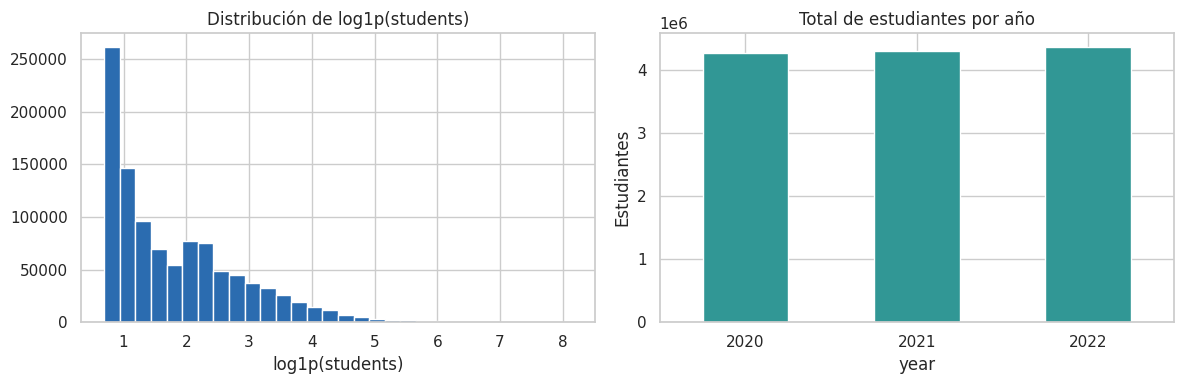

In [8]:
df = pd.read_parquet("educacion_superior_limpio.parquet").dropna(
    subset=["students"]
)

print("Filas y columnas:", df.shape)
print("\nResumen de 'students':")
print(df["students"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log1p(df["students"]), bins=30, color="#2b6cb0")
axes[0].set_title("Distribución de log1p(students)")
axes[0].set_xlabel("log1p(students)")

if "year" in df.columns:
  df.groupby("year")["students"].sum().plot(
      kind="bar", ax=axes[1], color="#319795"
  )
  axes[1].set_title("Total de estudiantes por año")
  axes[1].set_ylabel("Estudiantes")
  axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [9]:
def crear_features_simples(data):
  d = data.copy()

  if "year" in d.columns:
    d["anios_desde_2020"] = pd.to_numeric(d["year"], errors="coerce") - 2020

  if "age_group" in d.columns:
    d["es_18_24"] = (d["age_group"].astype(str) == "18-24").astype(int)

  return d


df_fe = crear_features_simples(df)
del df
gc.collect()

488

In [10]:
X = df_fe.drop(columns=["students"])
y = df_fe["students"]

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
del df_fe, X, y
gc.collect()

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (833928, 9) | Test: (208482, 9)


In [12]:
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]

prep = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler(with_mean=False)),
        ]),
        num_cols,
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]),
        cat_cols,
    ),
])

In [13]:
prep2 = ColumnTransformer([
    ("alta", TargetEncoder(target_type="continuous"), ["career", "institution"]),
    ("baja", OneHotEncoder(handle_unknown="ignore"), ["state", "area", "age_group"]),
    ("num", StandardScaler(), ["year", "sex"]),
])

## **Modelado**

In [14]:
cv = KFold(n_splits=3, shuffle=True, random_state=42)

In [15]:
pipe_ridge = Pipeline([
    ("prep", prep),
    ("ridge", Ridge(random_state=42)),
])

grid_ridge = GridSearchCV(
    pipe_ridge,
    {"ridge__alpha": [0.1, 1.0, 10.0, 100.0]},
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
)
grid_ridge.fit(X_train, y_train)

print("Mejores parámetros Ridge:", grid_ridge.best_params_)
print(f"RMSE en CV (Ridge): {-grid_ridge.best_score_:,.2f}")

Mejores parámetros Ridge: {'ridge__alpha': 0.1}
RMSE en CV (Ridge): 31.51


In [16]:
base = DummyRegressor(strategy="mean")
base.fit(X_train, y_train)

DummyRegressor()

In [17]:
prep2 = ColumnTransformer([
    ("alta", TargetEncoder(target_type="continuous"), ["career", "institution"]),
    ("baja", OneHotEncoder(handle_unknown="ignore"), ["state", "area", "age_group"]),
    ("num", StandardScaler(), ["year", "sex"]),
])

In [18]:
pipe_ridge2 = Pipeline([
    ("prep", prep2),
    ("ridge", Ridge(random_state=42)),
])

grid_ridge2 = GridSearchCV(
    pipe_ridge2,
    {"ridge__alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]},
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
)
grid_ridge2.fit(X_train, y_train)

print("Mejores parámetros Ridge 2:", grid_ridge2.best_params_)
print(f"RMSE en CV (Ridge 2): {-grid_ridge2.best_score_:,.2f}")

Mejores parámetros Ridge 2: {'ridge__alpha': 0.01}
RMSE en CV (Ridge 2): 32.78


In [19]:
X_sub = X_train.sample(150_000, random_state=42)
y_sub = y_train.loc[X_sub.index]

pipe_mlp = Pipeline([
    ("prep", prep2),
    ("mlp", MLPRegressor(early_stopping=True, max_iter=200, random_state=42)),
])

params_mlp = {
    "mlp__hidden_layer_sizes": [(32,), (64,), (64, 32)],
    "mlp__alpha": [0.0001, 0.001, 0.01],
    "mlp__learning_rate_init": [0.001, 0.01],
}

search_mlp = RandomizedSearchCV(
    pipe_mlp,
    params_mlp,
    n_iter=6,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=2,
)
search_mlp.fit(X_sub, y_sub)

print("Mejores parámetros MLP:", search_mlp.best_params_)
print(f"RMSE en CV (MLP, submuestra): {-search_mlp.best_score_:,.2f}")

# Reentrenar el mejor MLP con todo el conjunto de entrenamiento
mejor_mlp = search_mlp.best_estimator_
mejor_mlp.fit(X_train, y_train)

Mejores parámetros MLP: {'mlp__learning_rate_init': 0.01, 'mlp__hidden_layer_sizes': (64,), 'mlp__alpha': 0.0001}
RMSE en CV (MLP, submuestra): 29.83


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('alta',
                                                  TargetEncoder(target_type='continuous'),
                                                  ['career', 'institution']),
                                                 ('baja',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['state', 'area',
                                                   'age_group']),
                                                 ('num', StandardScaler(),
                                                  ['year', 'sex'])])),
                ('mlp',
                 MLPRegressor(early_stopping=True, hidden_layer_sizes=(64,),
                              learning_rate_init=0.01, random_state=42))])

## **Evaluación**

In [25]:
def metricas(modelo, nombre):
  pred = modelo.predict(X_test)
  return {
      "modelo": nombre,
      "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
      "MAE": mean_absolute_error(y_test, pred),
      "R2": r2_score(y_test, pred),
  }

resultados = pd.DataFrame([
    #metricas(base, "Línea base (promedio)"),
    metricas(grid_ridge, "Ridge original"),
    #metricas(grid_ridge2, "Ridge + TargetEncoder"),
    metricas(mejor_mlp, "MLP"),
]).round(3)
resultados

,modelo,RMSE,MAE,R2
0,Ridge original,31.271,12.598,0.243
1,MLP,27.374,9.966,0.420


---

In [21]:
base_mediana = DummyRegressor(strategy="median")
base_mediana.fit(X_train, y_train)

DummyRegressor(strategy='median')

In [22]:
from sklearn.compose import TransformedTargetRegressor

mlp_log = TransformedTargetRegressor(
    regressor=search_mlp.best_estimator_,
    func=np.log1p,
    inverse_func=np.expm1,
)
mlp_log.fit(X_train, y_train)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('prep',
                                                      ColumnTransformer(transformers=[('alta',
                                                                                       TargetEncoder(target_type='continuous'),
                                                                                       ['career',
                                                                                        'institution']),
                                                                                      ('baja',
                                                                                       OneHotEncoder(handle_unknown='ignore'),
                                                                                       ['state',
                                                                                        'area',
                                                                                        'age_group']),
                                                                                      ('num',
                                                                                       StandardScaler(),
                                                                                       ['year',
                                                                                        'sex'])])),
                                                     ('mlp',
                                                      MLPRegressor(early_stopping=True,
                                                                   hidden_layer_sizes=(64,),
                                                                   learning_rate_init=0.01,
                                                                   random_state=42))]))

In [23]:
resultados2 = pd.DataFrame([
    metricas(base, "Línea base (promedio)"),
    metricas(base_mediana, "Línea base (mediana)"),
    metricas(grid_ridge, "Ridge original"),
    metricas(grid_ridge2, "Ridge + TargetEncoder"),
    metricas(mejor_mlp, "MLP + TargetEncoder"),
    metricas(mlp_log, "MLP + TargetEncoder + log1p"),
]).round(3)
resultados2

,modelo,RMSE,MAE,R2
0,Línea base (promedio),35.941,13.760,-0.000
1,Línea base (mediana),36.906,10.647,-0.054
2,Ridge original,31.271,12.598,0.243
3,Ridge + TargetEncoder,32.549,12.667,0.180
4,MLP + TargetEncoder,27.374,9.966,0.420
5,MLP + TargetEncoder + log1p,30.805,8.657,0.265
